# Parte C — Scorecard: probabilidad → puntaje, puntos por variable, SHAP e hipótesis

Capa delgada sobre `src/` (núcleo §5.8): el notebook no calcula nada por su cuenta, solo llama funciones del
repositorio y muestra sus resultados o los resultados guardados. **Se edita este `.py`; el `.ipynb` lo genera
`python run.py notebooks`.**

**Convención (C §3.1):** $y = 1$ malo, $p = \text{PD} = P(y = 1)$; odds de **buen** pagador $o = (1 - p)/p$;
$\text{score} = \text{offset} - \text{factor}\cdot\text{logit}(p)$ con $\text{factor} = \text{PDO}/\ln 2$ y
$\text{offset} = \text{base} - \text{factor}\cdot\ln(\text{odds\_base})$: **mayor puntaje = menor riesgo**.

**Qué lee:** la config `configs/scorecard/base.yaml`; la logística de la Parte B (`models/pd_logistica.joblib`), el
preprocesador y los datos de la Parte A (`models/preprocesador_pd.json`, `data/processed/loans_pd.parquet`); los
resultados guardados de C4 y C6 (`results/data/scorecard/shap_mlp.json`, `scorecard_mlp.json`, `hipotesis.json`) y
las figuras del blog (`blog/docs/figures/sc-*.png`). **No escribe** en `data/`, `models/`, `results/`, `configs/` ni
`blog/`: la única figura que dibuja va a una carpeta temporal.

**Qué responde a `SET`:** las secciones 1 a 4 se calculan **en vivo** con la config elegida; las secciones 5 y 6
leen resultados guardados con la config por defecto (base 600, odds 50:1, PDO 20) y **no cambian** con `SET`.

Para la modificación en vivo, cambia `SET` (mismas claves que `--set`) y corre todo. Ejemplos:

- `SET = {"scorecard.pdo": 40}`: los puntos de cada variable y la separación entre bandas se **duplican** alrededor
  del ancla (los puntajes se alejan del valor base); el orden de los clientes no cambia, así que cada banda tiene los
  mismos créditos.
- `SET = {"scorecard.base": 500}`: todos los puntajes (puntos base, cortes de las bandas) **bajan 100**; los puntos
  por variable no cambian.
- `SET = {"scorecard.odds_base": 20}`: se **desplaza el offset** ($\text{factor}\cdot\ln(50/20)$ más): todos los
  puntajes suben esa cantidad y los puntos por variable no cambian.

## 1. Parámetros y configuración resuelta

`config_notebook` aplica `SET` con el mismo cargador del CLI (una clave inexistente es un error) e imprime la config.

In [1]:
CONFIG = "configs/scorecard/base.yaml"
SET = {}

In [2]:
import tempfile
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

from src.common.notebooks import config_notebook

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)

cfg = config_notebook(CONFIG, SET)
carpeta = Path(tempfile.mkdtemp(prefix="scorecard_"))  # solo para la figura en vivo de la sección 2; no se imprime

Configuración final resuelta:
scorecard:
  base: 600
  odds_base: 50
  pdo: 20
modelo: logistica
rutas:
  modelo: models/pd_logistica.joblib
  preprocesador: models/preprocesador_pd.json
  datos: data/processed/loans_pd.parquet
  features: configs/features.yaml
distribucion:
  percentiles_tabla:
  - 1
  - 5
  - 25
  - 50
  - 75
  - 95
  - 99
  percentiles_rango:
  - 1
  - 99
  fraccion_min_categoria: 0.01
  ancho_bin: 10
  n_bandas: 10
salida: results/data/scorecard


## 2. Probabilidad → puntaje (en vivo)

`parametros_scorecard` (C1) calcula `factor` y `offset` con la config elegida; `score_desde_pd` convierte unas PD de
ejemplo en puntaje. La segunda fila es la **PD del ancla** (odds `odds_base`:1), que `pd_desde_score` obtiene del
puntaje `base`: por construcción, su puntaje es exactamente `base`.

In [3]:
from src.scorecard.scorecard import parametros_scorecard, pd_desde_score, score_desde_pd

params = parametros_scorecard(cfg["scorecard"])
print(f"base {params['base']:g} · odds_base {params['odds_base']:g}:1 · PDO {params['pdo']:g} · "
      f"factor {params['factor']:.4f} · offset {params['offset']:.4f}")

PD_EJEMPLO = [0.01, pd_desde_score(params["base"], params), 0.1, 0.5]  # solo para mostrar
pd.DataFrame({"PD": PD_EJEMPLO, "puntaje": score_desde_pd(PD_EJEMPLO, params)}).round(4)

base 600 · odds_base 50:1 · PDO 20 · factor 28.8539 · offset 487.1229


,PD,puntaje
0,0.0100,619.7100
1,0.0196,600.0000
2,0.1000,550.5214
3,0.5000,487.1229


La figura `sc-transformacion` dibujada con estos parámetros en la carpeta temporal. La **segunda curva es siempre
PDO 40** (fija en `src/viz/figs_scorecard.py`, con la misma base y odds); si `SET` pide PDO 40, las dos curvas
coinciden.

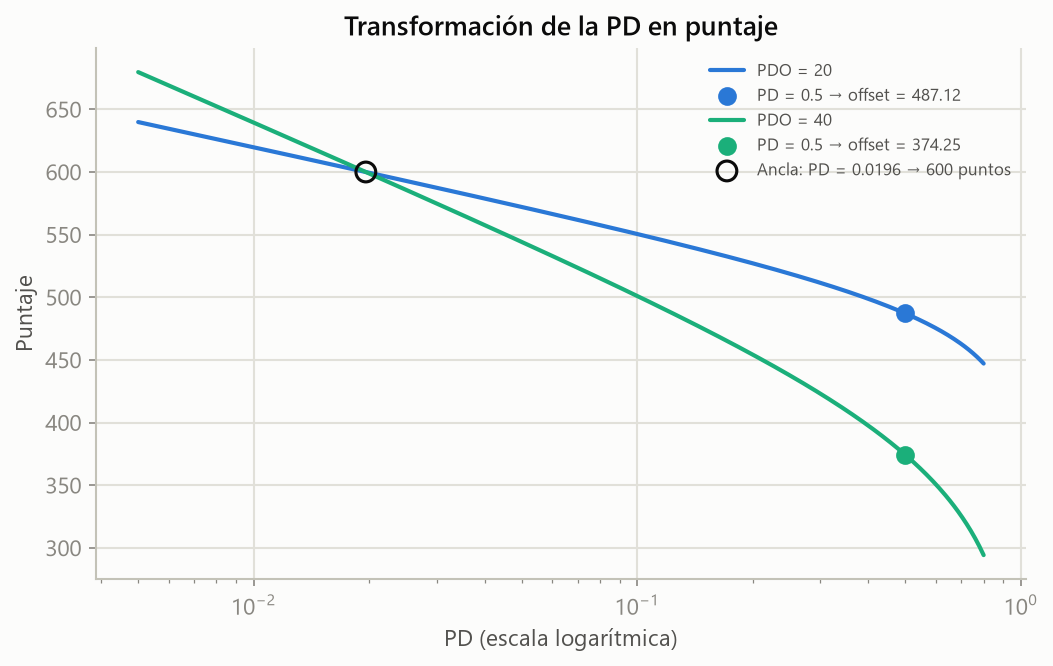

In [4]:
from src.viz.figs_scorecard import datos_transformacion, figura_transformacion
from src.viz.style import aplicar_estilo

aplicar_estilo()
display(Image(filename=str(figura_transformacion(datos_transformacion(params), carpeta))))

## 3. Scorecard de la logística (en vivo)

`preparar_splits` carga los datos, el preprocesador (ajustado solo con train por la Parte A) y la logística de B3;
`construir_scorecard` (C3) pasa el logit a puntaje con la config elegida, reparte los puntos por variable y comprueba
que puntos base + Σ puntos = puntaje en los tres splits. No escribe nada. El comando equivalente en la terminal (ese
sí escribe `scorecard.json` en `results/data/scorecard/`, salvo que se añada `--set salida=<otra carpeta>`):

`python run.py scorecard --config configs/scorecard/base.yaml --set scorecard.pdo=40`

In [5]:
from src.scorecard.puntos import construir_scorecard, preparar_splits

preparado = preparar_splits(cfg)
sc = construir_scorecard(cfg, preparado)
print(f"Puntos base: {sc['puntos_base']:.4f} (factor {sc['factor']:.4f}, offset {sc['offset']:.4f})")
print(f"Error máximo de aditividad: {sc['aditividad']['error_max']:.3e} (tolerancia {sc['aditividad']['tolerancia']:.0e})")

Puntos base: 525.9616 (factor 28.8539, offset 487.1229)
Error máximo de aditividad: 1.137e-13 (tolerancia 1e-09)


Puntos por valor crudo de dos numéricas (percentiles de **train**) y por categoría del plazo. En una numérica los
puntos valen 0 en la media transformada de train y son planos fuera del recorte $[p_1, p_{99}]$.

In [6]:
entradas = {e["nombre"]: e for e in sc["puntos_por_variable"]}
for nombre in ("annual_inc", "revol_util"):
    print(f"{nombre} — {entradas[nombre]['etiqueta_es']}")
    display(pd.DataFrame(entradas[nombre]["tabla"]).round(2))
print(f"term — {entradas['term']['etiqueta_es']}")
pd.DataFrame(entradas["term"]["categorias"]).round(4)

annual_inc — Ingreso anual (USD)


,percentil,valor,puntos
0,1,15056.58,-22.90
1,5,25000.00,-14.37
2,25,41600.00,-5.81
3,50,60000.00,0.35
4,75,82500.00,5.71
5,95,140000.00,14.61
6,99,230000.00,22.96


revol_util — Uso de tus cupos rotativos (%)


,percentil,valor,puntos
0,1,0.0,20.06
1,5,6.1,17.78
2,25,33.8,7.44
3,50,56.4,-0.99
4,75,75.6,-8.15
5,95,92.9,-14.61
6,99,97.6,-16.36


term — Plazo


,categoria,etiqueta,beta,puntos,fraccion_train
0,36 months,36 meses,-0.5012,14.4627,0.8297
1,60 months,60 meses,0.5013,-14.4650,0.1703


Rango de puntos de las 15 variables (numéricas: $|\text{puntos}(p_{99}) - \text{puntos}(p_1)|$; categóricas: entre las
categorías con al menos `fraccion_min_categoria` de train). Los rangos de numéricas y categóricas **no son
comparables** entre sí: miden cosas distintas (C §3.2).

In [7]:
(pd.DataFrame(sc["puntos_por_variable"])[["nombre", "etiqueta_es", "tipo", "rango_puntos"]]
 .sort_values("rango_puntos", ascending=False).round(2).reset_index(drop=True))

,nombre,etiqueta_es,tipo,rango_puntos
0,annual_inc,Ingreso anual (USD),num,45.86
1,revol_util,Uso de tus cupos rotativos (%),num,36.42
2,inq_last_6mths,Consultas de crédito en los últimos 6 meses,num,29.26
3,term,Plazo,cat,28.93
4,revol_bal,Saldo en tarjetas de crédito (USD),num,28.76
5,loan_amnt,Monto solicitado (USD),num,26.24
6,open_acc,Líneas de crédito abiertas,num,22.50
7,purpose,Destino del préstamo,cat,22.24
8,total_acc,Total de líneas de crédito en tu historial,num,12.70
9,delinq_2yrs,Moras de 30+ días en los últimos 2 años,num,10.16


Bandas de test (deciles del puntaje de **train**; banda 0 = menor puntaje = más riesgo): rango de puntaje
$[\text{desde}, \text{hasta})$, número de créditos, PD media predicha y tasa de malos observada.

In [8]:
pd.DataFrame(sc["distribucion_scores"]["test"]["bandas"]).round(4)

,banda,desde,hasta,n,puntaje_medio,pd_media,tasa_malos
0,0,NaN,511.7546,12187,501.5812,0.3790,0.4484
1,1,511.7546,523.3343,9776,517.7160,0.2579,0.3432
2,2,523.3343,530.3575,7571,527.0378,0.2007,0.3081
3,3,530.3575,535.4585,6889,532.9940,0.1695,0.2770
4,4,535.4585,539.9539,6768,537.7329,0.1476,0.2478
5,5,539.9539,544.3234,6738,542.1207,0.1295,0.2097
6,6,544.3234,548.9247,6603,546.5987,0.1130,0.1817
7,7,548.9247,554.2525,6433,551.4932,0.0971,0.1525
8,8,554.2525,561.6472,6130,557.6106,0.0801,0.1188
9,9,561.6472,NaN,5059,568.5835,0.0571,0.0753


## 4. Un cliente: puntos base + puntos por variable = su puntaje (en vivo)

El crédito de test es el **primero de los explicados por SHAP** (`explicados.ids[0]` de `shap_mlp.json`), el mismo
de la sección 5. `puntos_cliente` (C8) toma su fila del preparado, reparte sus puntos por variable con la scorecard de
la sección 3 y lee sus valores crudos del parquet de la Parte A, antes del preprocesador: las categóricas como vienen
en el crudo (el preprocesador les quita los espacios y un vacío, NaN, pasa a la categoría `DESCONOCIDO`) y un vacío
numérico se imputa con la mediana de train.

In [9]:
from src.common.results import load_json
from src.scorecard.puntos import puntos_cliente

shap = load_json("results/data/scorecard/shap_mlp.json")
ID_CLIENTE = shap["explicados"]["ids"][0]

cliente = puntos_cliente(preparado, params, ID_CLIENTE)
print(f"Crédito {cliente['id']} ({cliente['split']})")
print(f"Puntos base: {cliente['puntos_base']:.2f} · Σ puntos por variable: {cliente['variables']['puntos'].sum():.2f} · "
      f"puntaje: {cliente['score']:.2f} (error de aditividad {cliente['error_aditividad']:.1e})")
cliente["variables"].round(2)

Crédito 13366576 (test)
Puntos base: 525.96 · Σ puntos por variable: -27.72 · puntaje: 498.24 (error de aditividad 0.0e+00)


,nombre,etiqueta_es,valor,puntos
0,loan_amnt,Monto solicitado (USD),10000.0,-0.31
1,term,Plazo,60 months,-14.46
2,emp_length,Antigüedad en el empleo,NaN,-5.30
3,home_ownership,Vivienda,RENT,-1.09
4,annual_inc,Ingreso anual (USD),31000.0,-10.75
5,purpose,Destino del préstamo,debt_consolidation,2.71
6,dti,Deuda mensual sobre ingreso mensual (%),9.18,1.25
7,delinq_2yrs,Moras de 30+ días en los últimos 2 años,0.0,0.57
8,antiguedad_credito_anios,Años de historial crediticio,17.412731,0.16
9,inq_last_6mths,Consultas de crédito en los últimos 6 meses,0.0,5.41


## 5. SHAP del MLP (resultados guardados; no cambia con `SET`)

Valores de Shapley intervencionales del **logit** del MLP de PD (C4): $\varphi_0 + \sum_j \varphi_j = \text{logit}$
de cada crédito explicado. No se recalcula aquí: es la parte lenta de C4 (sus tiempos, impresos abajo, están en
`tiempos_s` del JSON). Para regenerarlo (escribe en
`results/data/scorecard/`; con `--set salida=<otra carpeta>` no pisa lo versionado):

`python run.py scorecard --config configs/scorecard/mlp.yaml`

In [10]:
sc_mlp = load_json("results/data/scorecard/scorecard_mlp.json")
print(f"φ₀ (logit medio del fondo): {shap['phi0']:.4f}")
print(f"Eficiencia (φ₀ + Σφ = logit): error máx {shap['eficiencia']['error_max']:.1e} "
      f"(tolerancia {shap['eficiencia']['tolerancia']:.0e})")
v = shap["verificacion_logistica"]
print(f"Verificación con la logística (forma cerrada): error máx {v['error_max']:.1e} en {v['n']} créditos")
print(f"Estabilidad entre semillas (Spearman de la importancia): {shap['estabilidad']['spearman_importancia']:.4f}")
print("Tiempos de C4 (s):", {k: round(s, 1) for k, s in shap["tiempos_s"].items()})
print(f"Scorecard del MLP: puntos base {sc_mlp['puntos_base']:.4f}, aditividad {sc_mlp['aditividad']['error_max']:.1e}")

φ₀ (logit medio del fondo): -1.4367
Eficiencia (φ₀ + Σφ = logit): error máx 6.2e-15 (tolerancia 1e-09)
Verificación con la logística (forma cerrada): error máx 1.6e-15 en 200 créditos
Estabilidad entre semillas (Spearman de la importancia): 0.9857
Tiempos de C4 (s): {'preparacion': 1.8, 'shap_base': 44.7, 'estabilidad': 11.3, 'verificacion_logistica': 5.8, 'permutacion_logistica': 5.8, 'permutacion_mlp': 11.7}
Scorecard del MLP: puntos base 528.5769, aditividad 2.3e-13


Importancia global (media de $|\varphi|$ en test) con su dirección (numéricas: $\rho$ de Spearman entre el valor y
$\varphi$, positivo = más valor, más riesgo; NaN en las categóricas, que van en la tabla siguiente) y la caída media de AUC al
permutar la variable en test, para los dos modelos.

In [11]:
from src.scorecard.puntos import direccion_shap
from src.viz.figs_scorecard import SALIDA, datos_importancia

imp = datos_importancia(shap)
direccion = direccion_shap(shap, imp["nombres"])
pd.DataFrame({
    "variable": imp["nombres"],
    "media_abs_phi": imp["media_abs_phi"],
    "spearman": direccion["spearman"],
    "caida_auc_mlp": imp["caida"]["mlp"]["media"],
    "caida_auc_logistica": imp["caida"]["logistica"]["media"],
}).round(4)

,variable,media_abs_phi,spearman,caida_auc_mlp,caida_auc_logistica
0,term,0.3289,NaN,0.0621,0.0579
1,revol_util,0.2194,0.9949,0.0367,0.0369
2,annual_inc,0.1938,-0.9968,0.0386,0.0427
3,inq_last_6mths,0.1607,0.9250,0.0113,0.0101
4,open_acc,0.1243,0.9961,0.0116,0.0087
5,loan_amnt,0.1013,0.9964,0.0072,0.0095
6,total_acc,0.0891,-0.9952,0.0094,0.0081
7,purpose,0.0805,NaN,0.0070,0.0064
8,revol_bal,0.0682,-0.9936,0.0030,0.0034
9,emp_length,0.0605,NaN,0.0016,0.0003


Dirección de las categóricas: $\bar\varphi$ (media de $\varphi$ en el logit del MLP) de cada categoría entre los
créditos explicados de test y cuántos hay; positivo = esa categoría sube el logit de la PD (más riesgo).

In [12]:
direccion["categorias"].round(4)

,variable,categoria,phi_medio,n
0,term,36 months,-0.2207,719
1,term,60 months,0.6059,281
2,purpose,debt_consolidation,-0.0245,646
3,purpose,credit_card,-0.2011,197
4,purpose,home_improvement,-0.0498,54
5,purpose,major_purchase,-0.1470,15
6,purpose,small_business,0.5289,10
7,purpose,car,-0.1590,2
8,purpose,medical,0.1821,9
9,purpose,moving,0.1746,10


$\varphi$ del mismo cliente de la sección 4 (logit del MLP = $\varphi_0 + \sum_j \varphi_j$).

In [13]:
print(f"Crédito {shap['explicados']['ids'][0]} · logit del MLP: {shap['explicados']['logit'][0]:.4f}")
pd.DataFrame({"jugador": shap["metodo"]["jugadores"], "phi": shap["explicados"]["phi"][0]}).round(4)

Crédito 13366576 · logit del MLP: -0.4258


,jugador,phi
0,loan_amnt,0.0160
1,term,0.5369
2,emp_length,0.1901
3,home_ownership,0.0404
4,annual_inc,0.2390
5,purpose,-0.0168
6,dti,-0.0069
7,delinq_2yrs,-0.0101
8,antiguedad_credito_anios,-0.0054
9,inq_last_6mths,-0.1196


Figuras del blog (generadas con los resultados guardados).

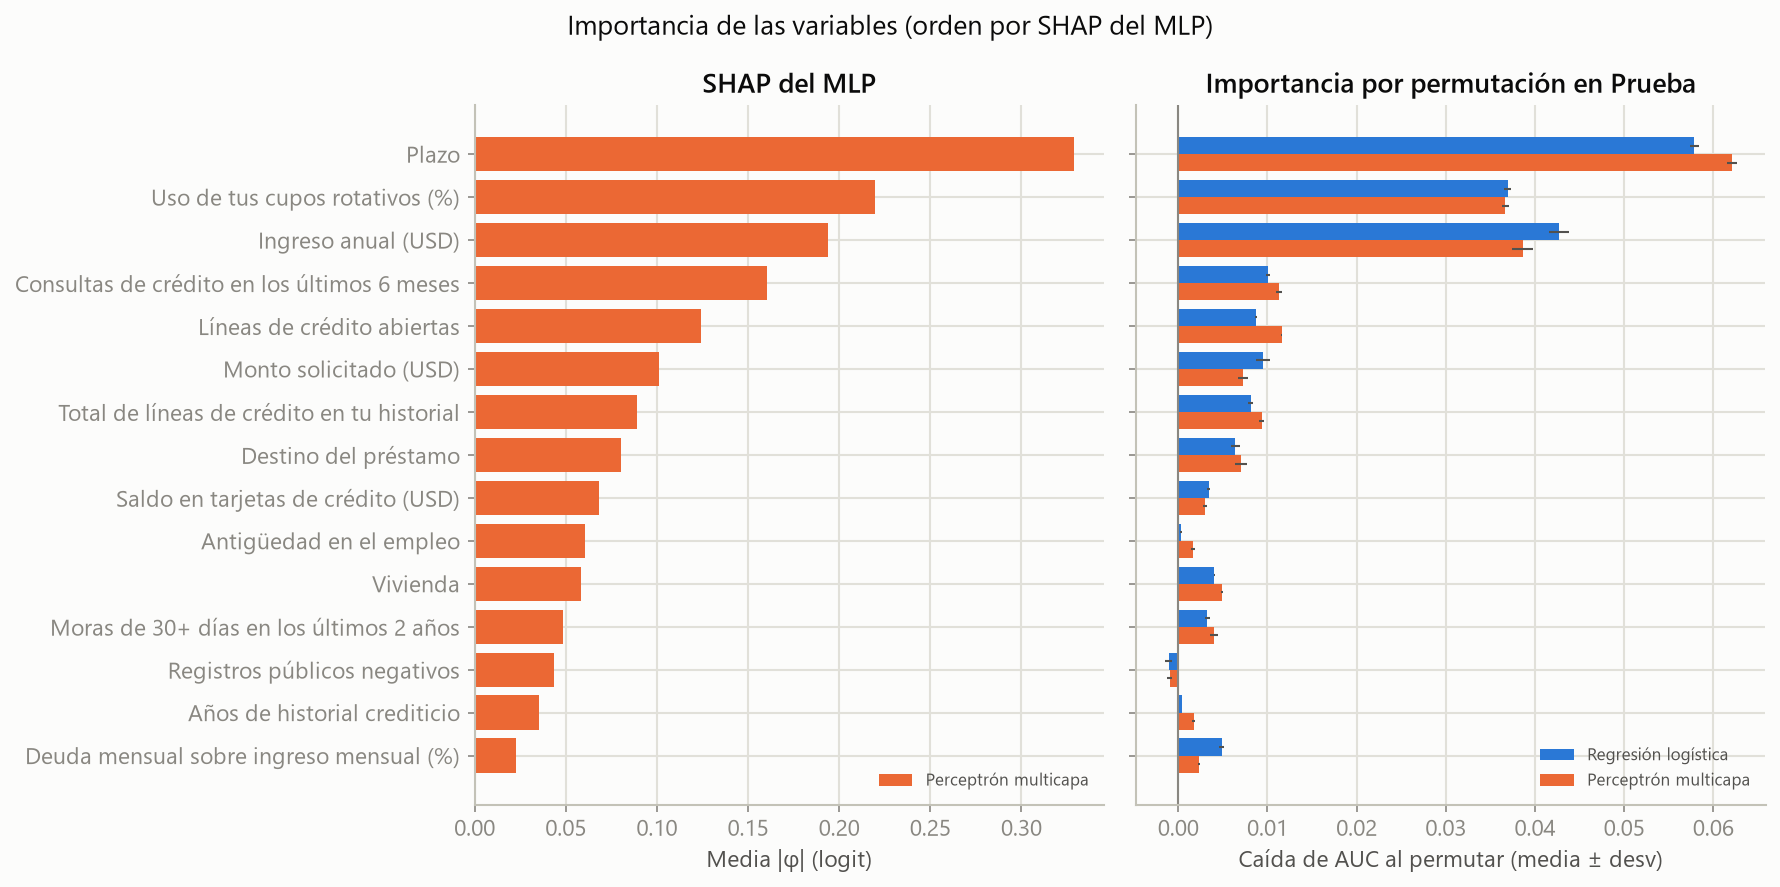

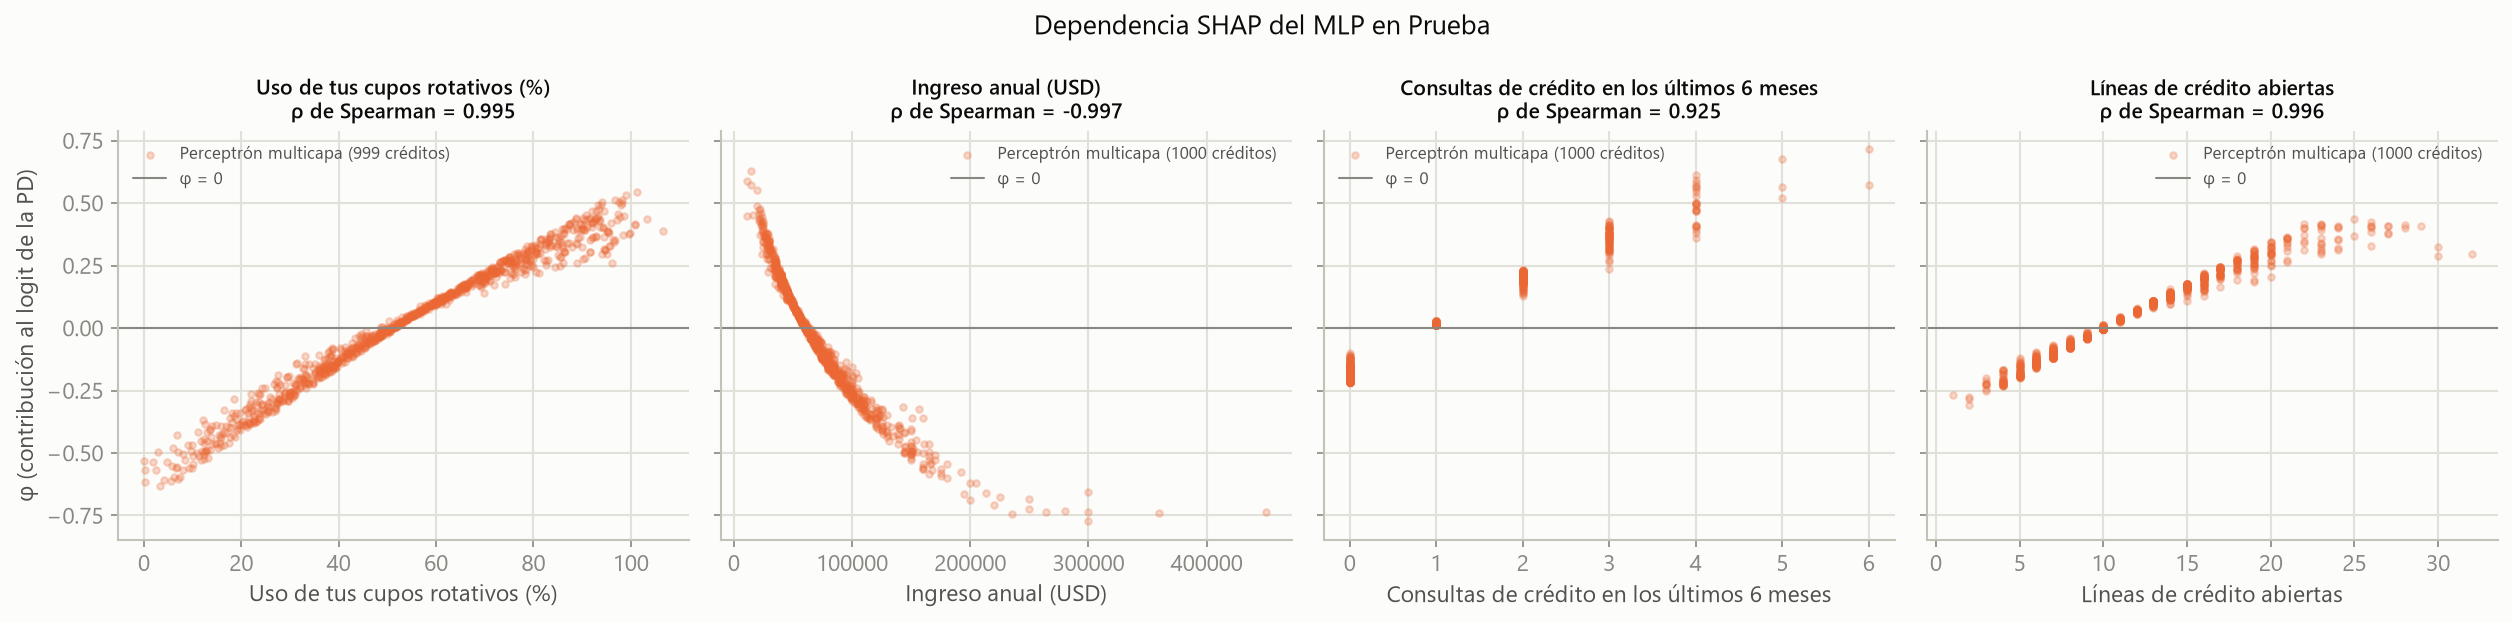

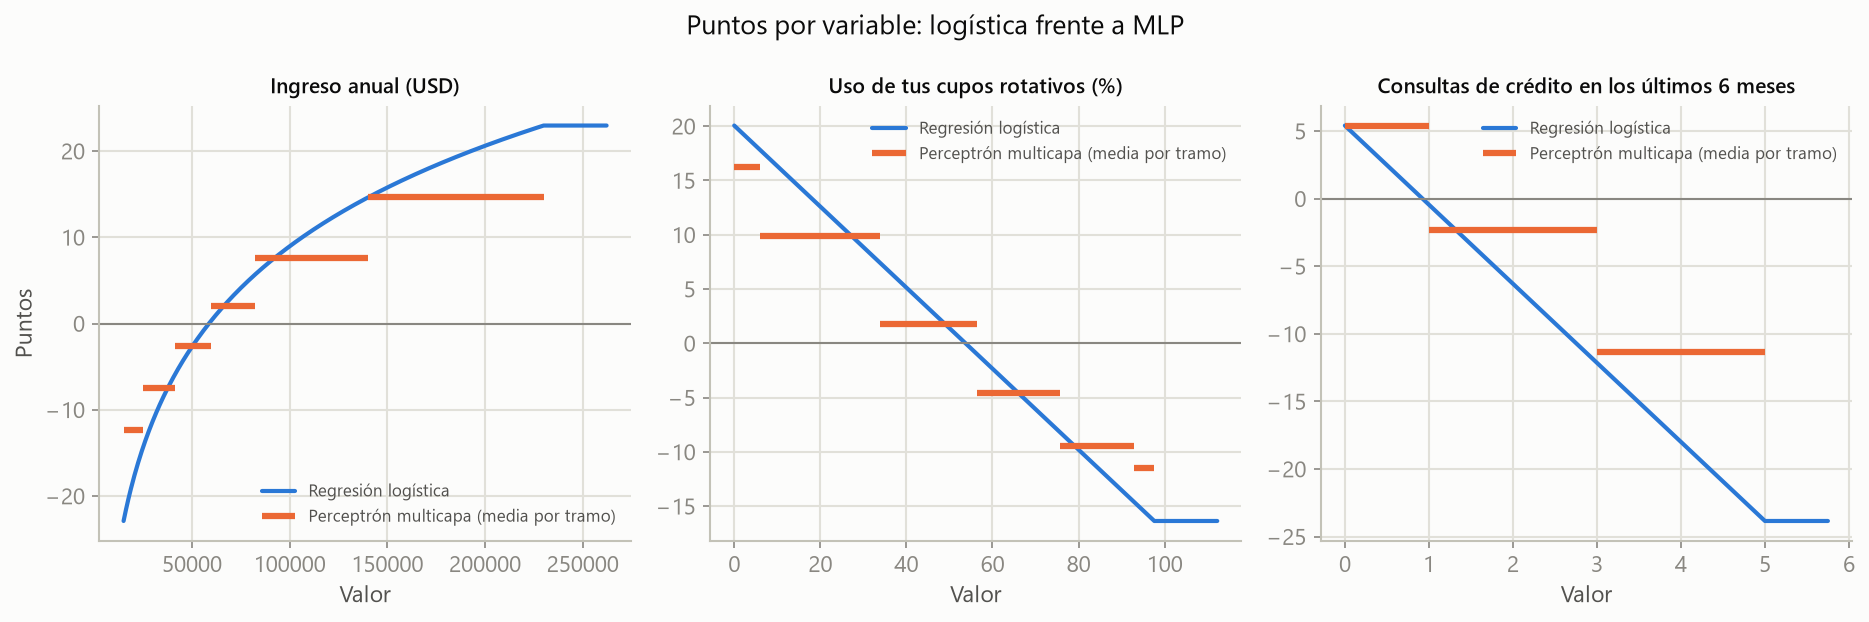

In [14]:
for nombre in ("sc-importancia.png", "sc-dependencia-shap.png", "sc-puntos-variable.png"):
    display(Image(filename=str(SALIDA / nombre)))

## 6. Cierre de las hipótesis (resultados guardados; no cambia con `SET`)

Las 11 hipótesis de riesgo con sus tres señales (EDA de train, SHAP del MLP y test fuera de tiempo), la compuerta de
la permutación (`relevante`) y el veredicto (C6). Es una asociación observada en los datos, no un efecto causal. Para
regenerarlo: `python -m src.scorecard.hipotesis`.

In [15]:
hip = load_json("results/data/scorecard/hipotesis.json")
for veredicto, regla in hip["criterio"]["reglas"].items():
    print(f"{veredicto}: {regla}")
pd.DataFrame([{
    "id": h["id"], "enunciado": h["enunciado"], "eda": h["eda"]["senal"], "shap": h["shap"]["senal"],
    "test": h["test"]["senal"], "relevante": h["shap"]["relevante"], "veredicto": h["veredicto"],
    "cambia_con_sensibilidad": h["cambia_con_sensibilidad"],
} for h in hip["hipotesis"]])

confirmada: EDA, SHAP y test a favor y permutación del MLP relevante.
refutada: Al menos 2 de {EDA, SHAP, test} en contra y ninguna a favor.
no concluyente: Todo lo demás (fuentes que discrepan, señal nula o permutación no relevante).


,id,enunciado,eda,shap,test,relevante,veredicto,cambia_con_sensibilidad
0,H1,Los créditos a 60 meses son más riesgosos que ...,a_favor,a_favor,a_favor,True,confirmada,False
1,H2,"A mayor razón deuda/ingreso (dti), mayor riesgo.",a_favor,a_favor,a_favor,True,confirmada,False
2,H3,"A mayor ingreso anual, menor riesgo.",a_favor,a_favor,a_favor,True,confirmada,False
3,H4,Más consultas de crédito en los últimos 6 mese...,a_favor,a_favor,a_favor,True,confirmada,False
4,H5,"A mayor uso de los cupos rotativos, mayor riesgo.",a_favor,a_favor,a_favor,True,confirmada,False
5,H6,Un historial crediticio más largo reduce el ri...,a_favor,a_favor,a_favor,True,confirmada,False
6,H7,Quien arrienda es más riesgoso que quien paga ...,a_favor,a_favor,a_favor,True,confirmada,False
7,H8,Los créditos para pequeña empresa son más ries...,a_favor,a_favor,a_favor,True,confirmada,False
8,H9,Tener registros públicos negativos aumenta el ...,a_favor,a_favor,en_contra,False,no concluyente,False
9,H10,"A mayor monto solicitado, mayor riesgo.",a_favor,a_favor,a_favor,True,confirmada,False


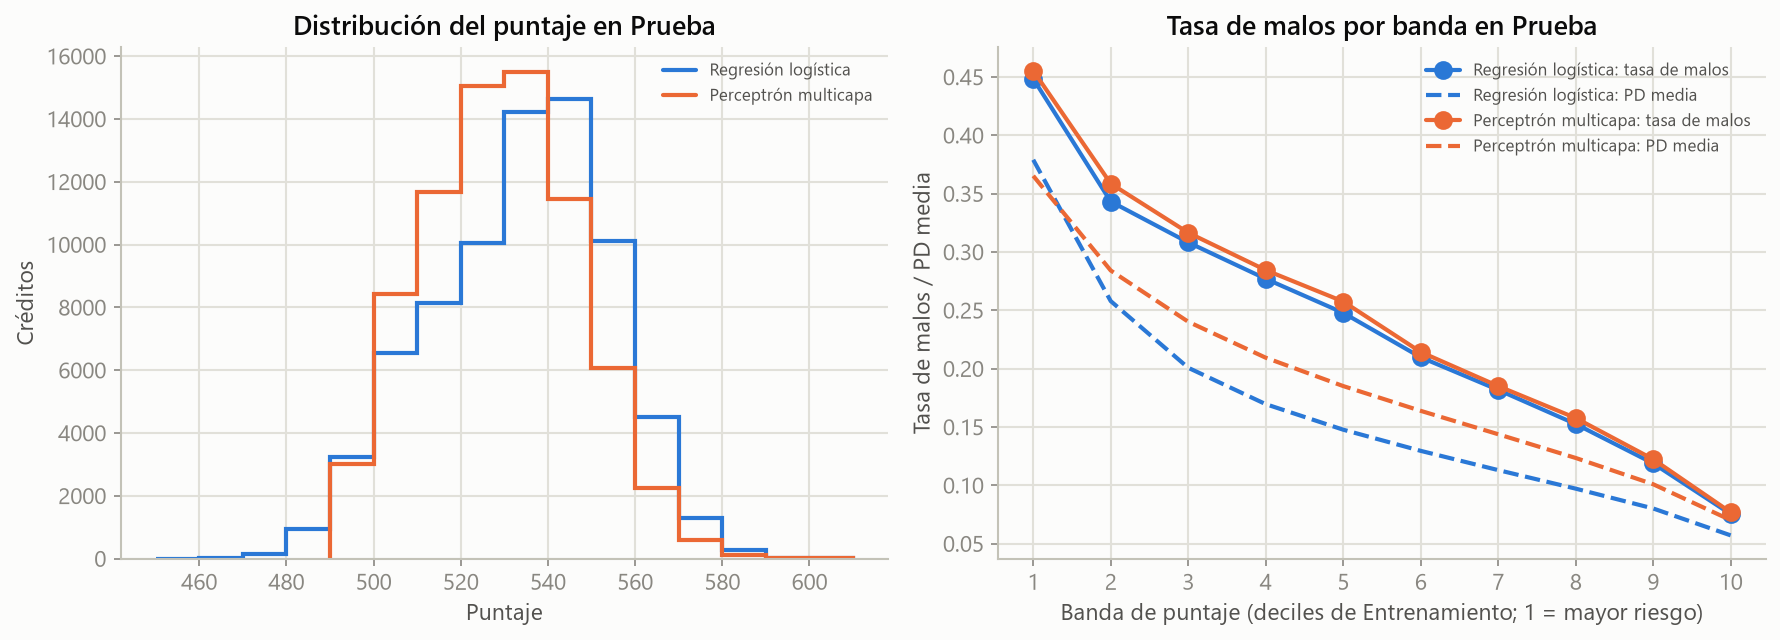

In [16]:
display(Image(filename=str(SALIDA / "sc-bandas.png")))